In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

In [2]:
df = pd.read_csv("heart.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
# Missing values check 
print(df.isnull().sum())


X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]


X = pd.get_dummies(X, drop_first=True, dtype=int)


X = X.fillna(X.median())

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
Features Shape: (918, 15)
Target Shape: (918,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (734, 15)
Testing Data: (184, 15)


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling Completed!")

Scaling Completed!


In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Neural Network": MLPClassifier(
        hidden_layer_sizes=(64, 32, 16),
        max_iter=500,
        random_state=42
    )
}

print("All Models Created!")

All Models Created!


In [7]:
for name, model in models.items():

    if name in ["Logistic Regression", "Neural Network"]:
        model.fit(X_train_scaled, y_train)

    else:
        model.fit(X_train, y_train)

    print(name, "Training Completed!")

Logistic Regression Training Completed!
Decision Tree Training Completed!
Random Forest Training Completed!
Neural Network Training Completed!


In [8]:
def calculate_metrics(actual, predicted):

    actual = np.array(actual)
    predicted = np.array(predicted)

    TP = np.sum((actual == 1) & (predicted == 1))
    TN = np.sum((actual == 0) & (predicted == 0))
    FP = np.sum((actual == 0) & (predicted == 1))
    FN = np.sum((actual == 1) & (predicted == 0))

    accuracy = (TP + TN) / (TP + TN + FP + FN)

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0

    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    return accuracy, precision, recall, f1

In [9]:
results = []

for name, model in models.items():

    if name in ["Logistic Regression", "Neural Network"]:
        train_data = X_train_scaled
        test_data = X_test_scaled

    else:
        train_data = X_train
        test_data = X_test

    # Training predictions
    train_pred = model.predict(train_data)

    # Testing predictions
    test_pred = model.predict(test_data)

    # Manual metrics
    train_metrics = calculate_metrics(y_train, train_pred)

    test_metrics = calculate_metrics(y_test, test_pred)

    results.append({
        "Model": name,
        "Train Accuracy": train_metrics[0],
        "Test Accuracy": test_metrics[0],
        "Precision": test_metrics[1],
        "Recall": test_metrics[2],
        "F1 Score": test_metrics[3]
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.862,0.886,0.872,0.931,0.900
1,Decision Tree,1.000,0.783,0.782,0.843,0.811
2,Random Forest,1.000,0.875,0.883,0.892,0.888
3,Neural Network,1.000,0.870,0.868,0.902,0.885


In [10]:
results_df["Overfitting Gap"] = (
    results_df["Train Accuracy"] -
    results_df["Test Accuracy"]
)

display(
    results_df[
        ["Model", "Train Accuracy",
         "Test Accuracy", "Overfitting Gap"]
    ].round(3)
)

,Model,Train Accuracy,Test Accuracy,Overfitting Gap
0,Logistic Regression,0.862,0.886,-0.023
1,Decision Tree,1.000,0.783,0.217
2,Random Forest,1.000,0.875,0.125
3,Neural Network,1.000,0.870,0.130


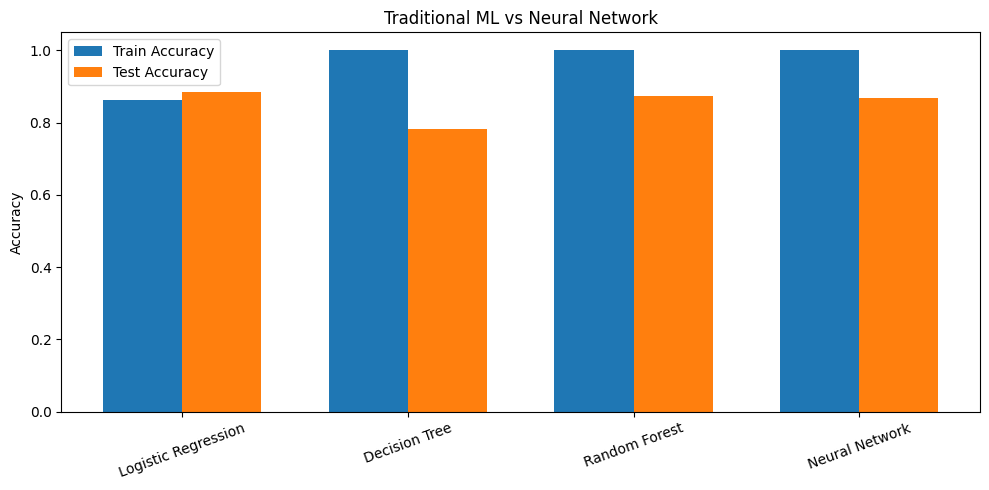

In [11]:
plt.figure(figsize=(10, 5))

x = np.arange(len(results_df))
width = 0.35

plt.bar(
    x - width / 2,
    results_df["Train Accuracy"],
    width,
    label="Train Accuracy"
)

plt.bar(
    x + width / 2,
    results_df["Test Accuracy"],
    width,
    label="Test Accuracy"
)

plt.xticks(x, results_df["Model"], rotation=20)

plt.ylabel("Accuracy")
plt.title("Traditional ML vs Neural Network")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
best_model = results_df.loc[
    results_df["Test Accuracy"].idxmax()
]

print("Best Model:", best_model["Model"])
print("Test Accuracy:", round(best_model["Test Accuracy"], 3))
print("Precision:", round(best_model["Precision"], 3))
print("Recall:", round(best_model["Recall"], 3))
print("F1 Score:", round(best_model["F1 Score"], 3))

print("\nConclusion:")
print("Models were compared using manually calculated metrics.")
print("Train-test accuracy gap was used to inspect overfitting.")
print("Deep Learning is not always better than traditional ML.")
print("The final model should be selected using multiple metrics.")

Best Model: Logistic Regression
Test Accuracy: 0.886
Precision: 0.872
Recall: 0.931
F1 Score: 0.9

Conclusion:
Models were compared using manually calculated metrics.
Train-test accuracy gap was used to inspect overfitting.
Deep Learning is not always better than traditional ML.
The final model should be selected using multiple metrics.
